In [1]:
import os
import urllib.request
import numpy as np
import pandas as pd

BASE_URL = "https://raw.githubusercontent.com/cCoolBoox/IFCD107-alumnado/main/datos/"

def dato(nombre):
    """Devuelve la ruta local de un archivo de datos del curso (lo descarga si no está)."""
    for carpeta in ("datos", "../datos", "../../datos"):
        ruta = os.path.join(carpeta, nombre)
        if os.path.exists(ruta):
            return ruta

    os.makedirs("datos", exist_ok=True)
    ruta = os.path.join("datos", nombre)
    urllib.request.urlretrieve(BASE_URL + nombre, ruta)
    return ruta

SEMILLA = 42

df = pd.read_csv(
    dato("reservas_turisdata.csv"),
    parse_dates=["fecha_reserva", "fecha_llegada"]
)

df["mes_llegada"] = df["fecha_llegada"].dt.month
df["temporada_alta"] = df["mes_llegada"].isin([1, 2, 3, 7, 8, 12]).astype(int)

print(df.shape)

(6000, 20)


In [2]:
precio_medio = df["precio_noche"].mean()
noches_medias = df["noches"].mean()

print(round(precio_medio, 2), "€ por noche ·", round(noches_medias, 1), "noches por reserva")

print(round(0.5 * noches_medias * precio_medio), "€ ≈ la mitad de las noches de una reserva media")

102.87 € por noche · 5.5 noches por reserva
284 € ≈ la mitad de las noches de una reserva media


In [3]:
COSTE_FN = 284   # cancelación no prevista: reserva media de 5,5 noches a ~103 €; solo se revende la mitad (0,5 × 5,52 × 102,87 ≈ 284 €)
COSTE_FP = 103   # falsa alarma: una noche de compensación (otro alojamiento y una disculpa) ≈ precio medio de una noche

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

Xp = pd.get_dummies(df[["tipo_habitacion"]], drop_first=True).astype(int)
Xp["temporada_alta"] = df["temporada_alta"]
yp = df["precio_noche"]
Xp_train, Xp_test, yp_train, yp_test = train_test_split(Xp, yp, test_size=0.2, random_state=SEMILLA)
print(Xp.shape, Xp_train.shape, Xp_test.shape)

(6000, 4) (4800, 4) (1200, 4)


In [5]:
modelos = {
    "Referencia (media)": DummyRegressor(strategy="mean"),
    "Regresión lineal": LinearRegression(),
    "Lineal con interacciones": make_pipeline(PolynomialFeatures(degree=2, interaction_only=True, include_bias=False), LinearRegression()),
}
filas = {}
for nombre, modelo in modelos.items():
    modelo.fit(Xp_train, yp_train)
    pred = modelo.predict(Xp_test)
    filas[nombre] = {"MAE (€)": mean_absolute_error(yp_test, pred),
                     "RMSE (€)": mean_squared_error(yp_test, pred) ** 0.5,
                     "R²": r2_score(yp_test, pred)}
resultados_precio = pd.DataFrame(filas).T.round(3)
resultados_precio

,MAE (€),RMSE (€),R²
Referencia (media),25.564,33.328,-0.002
Regresión lineal,7.239,9.704,0.915
Lineal con interacciones,6.758,8.936,0.928


In [6]:
lineal = modelos["Regresión lineal"]
print(pd.Series(lineal.coef_, index=Xp.columns).round(1))
print("Precio base (estándar en temporada baja):", round(lineal.intercept_, 1), "€")

tipo_habitacion_familiar     45.0
tipo_habitacion_suite       101.2
tipo_habitacion_superior     28.4
temporada_alta               22.4
dtype: float64
Precio base (estándar en temporada baja): 67.3 €


In [7]:
from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score,
                             precision_recall_curve, average_precision_score)
import matplotlib.pyplot as plt

columnas_num = ["antelacion_dias", "noches", "adultos", "ninos", "precio_noche",
                "peticiones_especiales", "cliente_repetidor", "cancelaciones_previas", "temporada_alta"]
columnas_cat = ["tipo_habitacion", "regimen", "canal", "pais_origen", "tarifa", "deposito"]
X, y = df[columnas_num + columnas_cat], df["cancelada"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEMILLA, stratify=y)

prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]), columnas_num),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore", drop="if_binary"))]), columnas_cat),
])
logit = Pipeline([("prep", prep), ("clf", LogisticRegression(max_iter=1000))])
tonto = Pipeline([("prep", clone(prep)), ("clf", DummyClassifier(strategy="most_frequent"))])
print(X_train.shape, X_test.shape, round(y_train.mean(), 3), round(y_test.mean(), 3))

(4800, 15) (1200, 15) 0.459 0.459


In [8]:
def metricas_umbral(y_real, proba, umbral):
    pred = (proba >= umbral).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_real, pred).ravel()
    return {"umbral": umbral, "VN": int(vn), "FP": int(fp), "FN": int(fn), "VP": int(vp),
            "precision": float(vp / (vp + fp)) if (vp + fp) else np.nan,
            "recall": float(vp / (vp + fn))}

def coste_total(y_real, proba, umbral, coste_fn, coste_fp):
    m = metricas_umbral(y_real, proba, umbral)
    return m["FN"] * coste_fn + m["FP"] * coste_fp

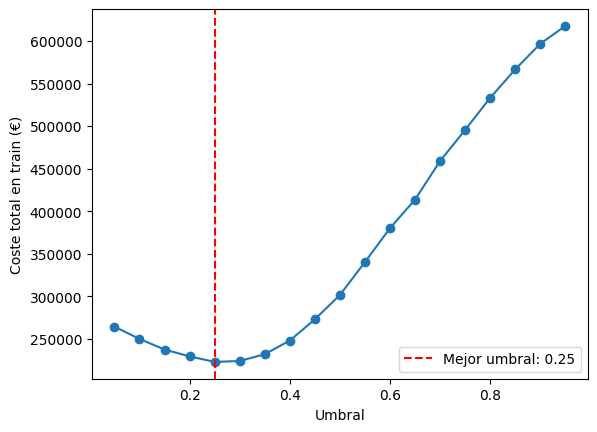

Umbral elegido: 0.25


In [9]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEMILLA)
proba_cv = cross_val_predict(logit, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
umbrales = np.arange(0.05, 0.96, 0.05)

def buscar_umbral(coste_fn, coste_fp):
    """Prueba todos los umbrales con las probabilidades de train y devuelve el de menor coste."""
    costes = []
    for u in umbrales:
        costes.append(coste_total(y_train, proba_cv, u, coste_fn, coste_fp))
    mejor = round(float(umbrales[np.argmin(costes)]), 2)
    return mejor, costes

mejor_umbral, costes = buscar_umbral(COSTE_FN, COSTE_FP)
plt.plot(umbrales, costes, marker="o")
plt.axvline(mejor_umbral, color="red", linestyle="--", label=f"Mejor umbral: {mejor_umbral}")
plt.xlabel("Umbral"); plt.ylabel("Coste total en train (€)"); plt.legend(); plt.show()
print("Umbral elegido:", mejor_umbral)

Coste en test sin modelo: 156,484 €
Coste en test con umbral 0.5: 78,439 €
Coste en test con umbral 0.25: 58,331 €
Ahorro frente a no hacer nada: 98,153 € (63%)
VN 204 · FP 445 · FN 44 · VP 507
Precisión 53% · Recall 92%


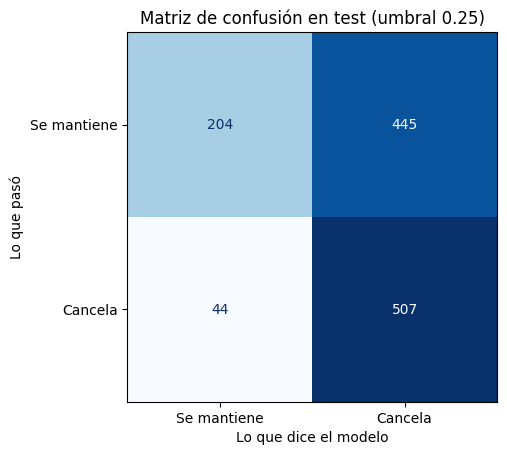

In [10]:
logit.fit(X_train, y_train)
tonto.fit(X_train, y_train)
proba_test = logit.predict_proba(X_test)[:, 1]

coste_sin_modelo = y_test.sum() * COSTE_FN
coste_05 = coste_total(y_test, proba_test, 0.5, COSTE_FN, COSTE_FP)
coste_elegido = coste_total(y_test, proba_test, mejor_umbral, COSTE_FN, COSTE_FP)
print("Coste en test sin modelo: {:,.0f} €".format(coste_sin_modelo))
print("Coste en test con umbral 0.5: {:,.0f} €".format(coste_05))
print("Coste en test con umbral {}: {:,.0f} €".format(mejor_umbral, coste_elegido))
ahorro = coste_sin_modelo - coste_elegido
print("Ahorro frente a no hacer nada: {:,.0f} € ({:.0%})".format(ahorro, ahorro / coste_sin_modelo))

m = metricas_umbral(y_test, proba_test, mejor_umbral)
print("VN {VN} · FP {FP} · FN {FN} · VP {VP}".format(**m))
print("Precisión {:.0%} · Recall {:.0%}".format(m["precision"], m["recall"]))
ConfusionMatrixDisplay.from_predictions(y_test, (proba_test >= mejor_umbral).astype(int),
                                        display_labels=["Se mantiene", "Cancela"], cmap="Blues", colorbar=False)
plt.title(f"Matriz de confusión en test (umbral {mejor_umbral})")
plt.xlabel("Lo que dice el modelo"); plt.ylabel("Lo que pasó")
plt.show()

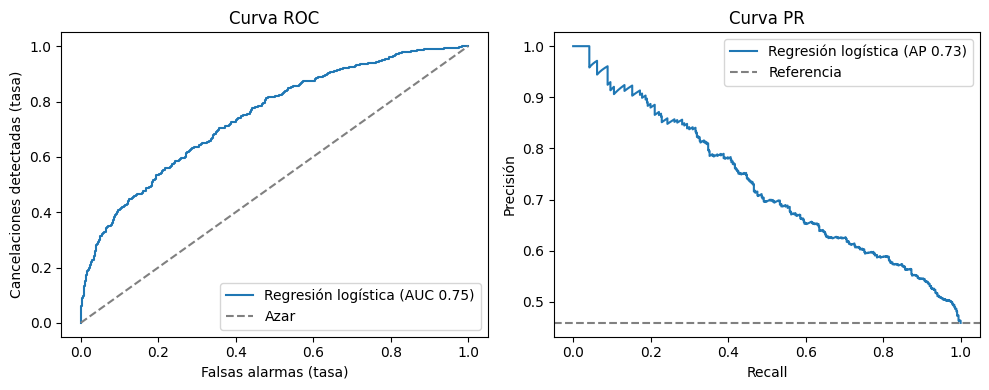

AUC 0.746 · AP 0.729 · referencia: AUC 0.500, AP 0.459


In [11]:
proba_tonto = tonto.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, proba_test)
prec, rec, _ = precision_recall_curve(y_test, proba_test)
auc, ap = roc_auc_score(y_test, proba_test), average_precision_score(y_test, proba_test)

fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
ejes[0].plot(fpr, tpr, label=f"Regresión logística (AUC {auc:.2f})")
ejes[0].plot([0, 1], [0, 1], "--", color="gray", label="Azar")
ejes[0].set(title="Curva ROC", xlabel="Falsas alarmas (tasa)", ylabel="Cancelaciones detectadas (tasa)")
ejes[1].plot(rec, prec, label=f"Regresión logística (AP {ap:.2f})")
ejes[1].axhline(y_test.mean(), linestyle="--", color="gray", label="Referencia")
ejes[1].set(title="Curva PR", xlabel="Recall", ylabel="Precisión")
ejes[0].legend(); ejes[1].legend()
plt.tight_layout(); plt.show()
print(f"AUC {auc:.3f} · AP {ap:.3f} · referencia: AUC {roc_auc_score(y_test, proba_tonto):.3f}, AP {average_precision_score(y_test, proba_tonto):.3f}")

In [12]:
hipotesis = [("la nuestra", COSTE_FN, COSTE_FP),
             ("FN el doble", COSTE_FN * 2, COSTE_FP),
             ("FP la mitad", COSTE_FN, COSTE_FP / 2),
             ("FP el doble", COSTE_FN, COSTE_FP * 2)]
filas = []
for nombre, coste_fn, coste_fp in hipotesis:
    umbral, costes = buscar_umbral(coste_fn, coste_fp)
    filas.append({"hipótesis": nombre, "COSTE_FN": coste_fn, "COSTE_FP": coste_fp,
                  "umbral_optimo": umbral, "coste_total": round(min(costes)),
                  "sin_modelo": round(y_train.sum() * coste_fn)})
sensibilidad = pd.DataFrame(filas)
print(sensibilidad)

     hipótesis  COSTE_FN  COSTE_FP  umbral_optimo  coste_total  sin_modelo
0   la nuestra       284     103.0           0.25       223121      625652
1  FN el doble       568     103.0           0.15       249011     1251304
2  FP la mitad       284      51.5           0.15       124506      625652
3  FP el doble       284     206.0           0.40       354720      625652


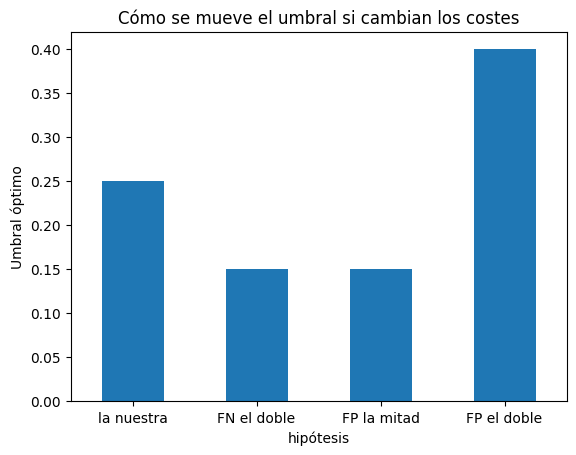

In [13]:
sensibilidad.plot.bar(x="hipótesis", y="umbral_optimo", legend=False, rot=0)
plt.ylabel("Umbral óptimo")
plt.title("Cómo se mueve el umbral si cambian los costes")
plt.show()